# Phát hiện bất thường trên chi tiết nhựa ép phun, chạy trên máy tính công nghiệp cấu hình yếu

**Học phần:** Đồ án tốt nghiệp (DATN) – HUST
**Bài toán:** camera chụp từng chi tiết nhựa (khung nhựa xanh, 1163×803 px) trên băng chuyền; máy tính cạnh
băng chuyền phải quyết định **OK / NG** cho từng chi tiết và chỉ ra vị trí lỗi. Chỉ có ảnh chi tiết tốt để học
(lỗi hiếm và đa dạng) → học không giám sát (anomaly detection): model học "thế nào là bình thường", chi tiết nào
lệch khỏi đó thì bị loại.

**Hướng giải:**

| Bước | Lựa chọn | Lý do |
|---|---|---|
| Kiểm tra dữ liệu | `partinspect-audit`: file trùng, ảnh NG chỉnh sửa từ ảnh train, số chi tiết vật lý | số liệu chỉ có giá trị khi tập test sạch |
| Chia dữ liệu | `partinspect-split`: test không trùng train, val/test tách theo khối ảnh liên tục, lỗi tổng hợp có mask chính xác | tránh rò rỉ dữ liệu |
| Mô hình | PaDiM, PatchCore (anomalib 2.7) với backbone ResNet-18 / Wide-ResNet-50 | các phương pháp chuẩn của benchmark MVTec AD, chỉ cần ảnh tốt |
| Tối ưu cho máy yếu | export OpenVINO, so sánh FP32 / FP16 / INT8 (trọng số) / INT8 (PTQ); đo độ trễ với **2 luồng CPU** | máy tính băng chuyền thường là CPU vài nhân, không có GPU |
| Đánh giá | AUROC, AP, recall / FPR tại ngưỡng chọn trên val, recall theo từng loại lỗi, pixel AUROC, AUPRO | đúng câu hỏi của nhà máy: bắt được bao nhiêu lỗi, loại nhầm bao nhiêu hàng tốt |
| Triển khai | `partinspect-serve`: theo dõi thư mục ảnh, tín hiệu OK/NG, log CSV, ảnh heatmap của hàng NG, cảnh báo trôi phân bố | nguyên mẫu trạm kiểm tra chỉ cần `openvino` + `opencv` |

**So với bản cũ** (notebook PaDiM/PatchCore năm trước, AUROC 0.998–1.0): kết quả cũ **không hợp lệ** —
55/60 ảnh test good là bản sao byte-by-byte của ảnh train, và cả 60 ảnh NG là ảnh train được sửa bằng Photoshop
(xem mục 1). Notebook này làm lại từ đầu với tập test sạch và báo cáo số liệu thật, kể cả những chỗ kết quả chưa tốt.

**Mã nguồn** nằm trong gói `partinspect` (`src/`); notebook chỉ gọi gói đó. Các bước huấn luyện (mục 3) đã chạy
trên Colab (GPU L4); kết quả được lưu trong `results/` nên notebook mặc định **chỉ đọc kết quả**
(`RUN_TRAINING = False`) và chạy được trên máy không có GPU.

## 0. Cài đặt và đường dẫn

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/HUST/DATN/IndustrialAnomalyDetection")
except ImportError:
    PROJECT = Path(os.environ.get("PROJECT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
RAW = Path(os.environ.get("RAW", PROJECT / "data/MyDataset"))  # bộ dữ liệu gốc (trên Drive: HUST/DATN/MyDataset)
if not RAW.exists() and (PROJECT.parent / "MyDataset").exists():
    RAW = PROJECT.parent / "MyDataset"
DATA = PROJECT / "data/prepared"
RESULTS = PROJECT / "results"
RUN_TRAINING = os.environ.get("RUN_TRAINING", "0") == "1"  # 1 = huấn luyện lại toàn bộ (cần GPU, ~1–2 giờ)
os.chdir(PROJECT)
if "partinspect" not in sys.modules:
    try:
        import partinspect  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{PROJECT}[dev]"], check=True)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partinspect import audit, metrics, report, synth

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("project:", PROJECT, "| raw data:", RAW, "| training:", RUN_TRAINING)

project: . | raw data: ./data/MyDataset | training: False


## 1. Kiểm tra bộ dữ liệu gốc

Bộ dữ liệu theo cấu trúc MVTec: `train/good` (301 ảnh), `test/good` (60), `test/NG` (60) + mask lỗi.
`partinspect-audit` làm ba phép kiểm tra:

1. **File trùng** giữa train và test (MD5).
2. **Ảnh NG được sửa từ ảnh train:** so ảnh NG với ảnh train gần nhất *ở ngoài vùng mask lỗi*. Hai lần chụp khác
   nhau luôn lệch nhau vì nhiễu cảm biến; nếu ngoài vùng lỗi hai ảnh gần như trùng khít thì ảnh NG được tạo bằng
   cách vẽ lỗi lên ảnh train.
3. **Số chi tiết vật lý:** mỗi chi tiết ép phun có vân bề mặt riêng. So vân (ảnh lọc thông cao trên một vùng nhựa
   trơn, sau khi căn chỉnh) giữa các ảnh: cùng một chi tiết → tương quan 0.89–0.99; khác chi tiết → 0.07–0.21.

In [2]:
rep = subprocess.run([sys.executable, "-m", "partinspect.audit", str(RAW), "--json", "reports/audit.json"],
                     capture_output=True, text=True)
print(rep.stdout)

exact duplicates across splits: 55 groups
    test/good/000.png == train/good/000.png
    test/good/001.png == train/good/001.png
    test/good/002.png == train/good/002.png
    test/good/003.png == train/good/003.png
    test/good/004.png == train/good/004.png
test/NG: 60/60 images are edited copies of a training image (difference outside the mask < 0.241; two separate photos differ by ~0.965)
good photos show 3 physical part(s):
    part 0: 149 photos: test/good/000-054; train/good/000-092, 094
    part 1: 5 photos: test/good/055-059
    part 2: 207 photos: train/good/093, 095-300



Minh hoạ phép kiểm tra 2: ảnh `test/NG/000` so với `train/good/000`. Ngoài vùng mask, chênh lệch trung bình chỉ
~0.04/255 (hai lần chụp thật khác nhau ~1/255) → cùng một bức ảnh; trong vùng mask, dấu tròn đã bị xoá.

chênh lệch ngoài mask: 0.042/255 | trong mask: 25.0/255


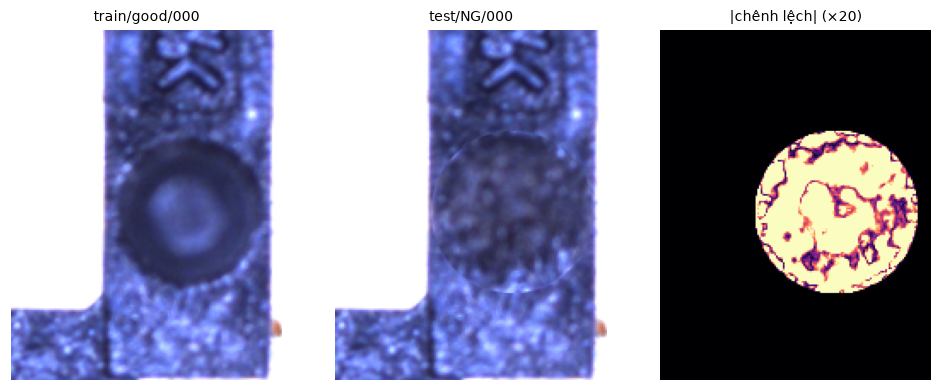

In [3]:
a = cv2.imread(str(RAW / "train/good/000.png"))
b = cv2.imread(str(RAW / "test/NG/000.png"))
m = cv2.imread(str(next((RAW / "ground_truth/NG").glob("000*"))), 0) > 0
diff = np.abs(a.astype(np.float32) - b.astype(np.float32)).mean(2)
print(f"chênh lệch ngoài mask: {diff[~m].mean():.3f}/255 | trong mask: {diff[m].mean():.1f}/255")
ys, xs = np.where(m)
y0, y1, x0, x1 = max(ys.min() - 60, 0), ys.max() + 60, max(xs.min() - 60, 0), xs.max() + 60
fig, ax = plt.subplots(1, 3, figsize=(9, 3.6))
for axi, img, t in zip(ax, [a, b, diff], ["train/good/000", "test/NG/000", "|chênh lệch| (×20)"]):
    if img.ndim == 3:
        axi.imshow(cv2.cvtColor(img[y0:y1, x0:x1], cv2.COLOR_BGR2RGB))
    else:
        axi.imshow(np.clip(img[y0:y1, x0:x1] * 20, 0, 255), cmap="magma")
    axi.set_title(t, fontsize=9)
    axi.axis("off")
plt.tight_layout()
plt.show()

**Kết luận kiểm tra:**

| Phát hiện | Hệ quả |
|---|---|
| `test/good/000–054` là bản sao byte-by-byte của `train/good/000–054` | model đã thấy chính ảnh test khi học |
| 60/60 ảnh `test/NG/i` = `train/good/i` + lỗi vẽ bằng Photoshop (xoá dấu tròn 000–029, xoá chữ khắc 030–059) | ảnh lỗi không phải lỗi thật; ảnh gốc của chúng nằm trong tập train |
| 301 + 60 ảnh good chỉ là **3 chi tiết vật lý**: A = ảnh 000–094 (gồm cả test 000–054), B = 093, 095–300, C = `test/good/055–059` | không đo được tỉ lệ loại nhầm trên *chi tiết mới* (xem mục 5) |
| `MyDataset_old` giống `MyDataset`, chỉ khác `test/good/055–059` cũng là bản sao | đã xoá (vào thùng rác Drive) |

→ AUROC 0.998–1.0 của bản cũ đo trên dữ liệu rò rỉ, không phản ánh chất lượng model.

## 2. Chia lại dữ liệu và tạo lỗi tổng hợp

`partinspect-split` (seed 0):

| Tập | Nội dung | Ghi chú |
|---|---|---|
| train | 201 ảnh good: `train/good/065–265` | |
| val | 30 ảnh good `271–300` + 30 ảnh lỗi tổng hợp (5 × 6 loại) | chỉ dùng để chọn ngưỡng |
| test | 65 ảnh good (`000–059` = nguồn của ảnh NG chỉnh sửa, + 5 ảnh chi tiết C) + 60 NG chỉnh sửa + 120 lỗi tổng hợp (20 × 6 loại) | |

Ảnh được đánh số theo thứ tự chụp và các ảnh liền nhau gần như giống hệt nhau, nên các khối được tách liên tục,
cách nhau 5 ảnh. (Lần chia đầu tiên lấy val ngẫu nhiên: ảnh val có hai ảnh hàng xóm trong train, điểm val thấp
giả tạo và ngưỡng chọn trên val loại tới 74–88% hàng tốt ở test khi chạy 512×736.)

**Lỗi tổng hợp** (`synth.py`) chỉ thay đổi pixel *bên trong* mask trả về (có unit test), nên mask là nhãn chính xác:
mất dấu tròn, mất chữ khắc (điền bằng vân nhựa thật lấy từ vùng trơn), vết xước, chấm bẩn, mẻ cạnh, vết cháy.

In [4]:
if RUN_TRAINING or not (DATA / "manifest.csv").exists():
    subprocess.run([sys.executable, "-m", "partinspect.split", str(RAW), "--out", str(DATA)], check=True)
man = pd.read_csv(DATA / "manifest.csv").fillna("")
print(man.groupby(["split", "label", "defect_type"]).size().rename("n").to_string())

split  label  defect_type 
test   NG     burn             20
              edge_chip        20
              edited_mark      30
              edited_text      30
              erased_text      20
              missing_mark     20
              scratch          20
              spot             20
       good                    65
train  good                   201
val    NG     burn              5
              edge_chip         5
              erased_text       5
              missing_mark      5
              scratch           5
              spot              5
       good                    30


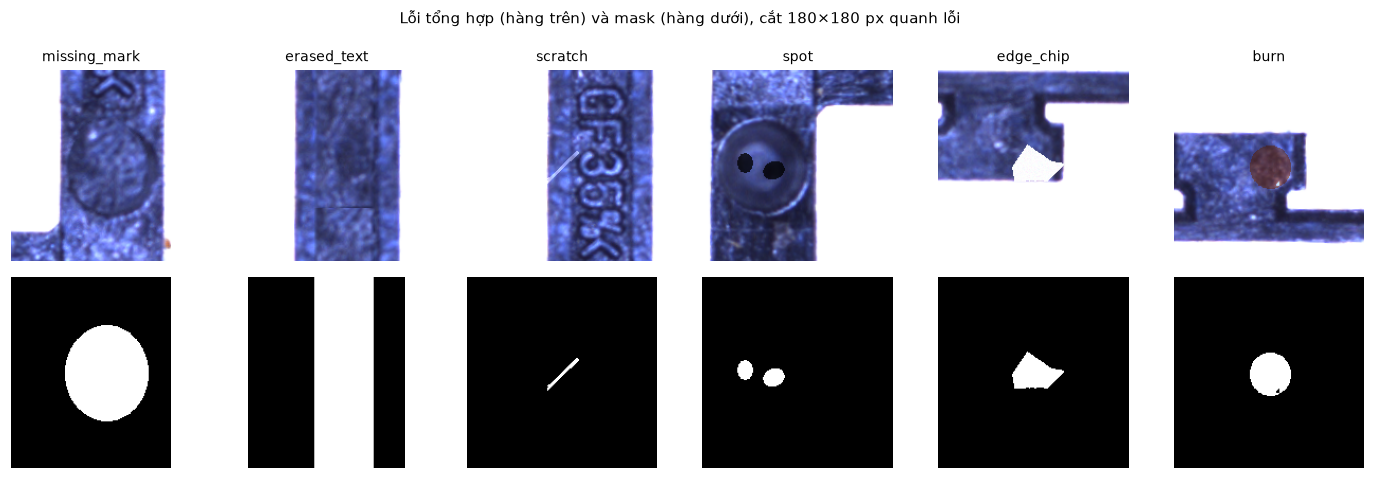

In [5]:
fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for j, kind in enumerate(synth.TYPES):
    r = man[(man.split == "test") & (man.defect_type == kind)].iloc[0]
    img = cv2.imread(str(DATA / r.path))
    mask = cv2.imread(str(DATA / r["mask"]), 0) > 0
    ys, xs = np.where(mask)
    cy, cx = int(ys.mean()), int(xs.mean())
    y0, x0 = max(cy - 90, 0), max(cx - 90, 0)
    ax[0, j].imshow(cv2.cvtColor(img[y0:y0 + 180, x0:x0 + 180], cv2.COLOR_BGR2RGB))
    ax[0, j].set_title(kind, fontsize=9)
    ax[1, j].imshow(mask[y0:y0 + 180, x0:x0 + 180], cmap="gray")
    for a_ in ax[:, j]:
        a_.axis("off")
plt.suptitle("Lỗi tổng hợp (hàng trên) và mask (hàng dưới), cắt 180×180 px quanh lỗi", fontsize=10)
plt.tight_layout()
plt.show()

In [6]:
print(subprocess.run([sys.executable, "-m", "partinspect.audit", str(DATA)], capture_output=True, text=True).stdout)

exact duplicates across splits: 0 groups
test/NG: 0/180 images are edited copies of a training image (difference outside the mask < 0.373; two separate photos differ by ~1.493)
good photos show 3 physical part(s):
    part 0: 5 photos: test/good/new_055, new_056, new_057, new_058, new_059
    part 1: 89 photos: test/good/orig_000, orig_001, orig_002, orig_003, orig_004, orig_005, orig_006, orig_007, orig_008, orig_009, orig_010, orig_011, orig_012, orig_013, orig_014, orig_015, orig_016, orig_017, orig_018, orig_019, orig_020, orig_021, orig_022, orig_023, orig_024, orig_025, orig_026, orig_027, orig_028, orig_029, orig_030, orig_031, orig_032, orig_033, orig_034, orig_035, orig_036, orig_037, orig_038, orig_039, orig_040, orig_041, orig_042, orig_043, orig_044, orig_045, orig_046, orig_047, orig_048, orig_049, orig_050, orig_051, orig_052, orig_053, orig_054, orig_055, orig_056, orig_057, orig_058, orig_059; train/good/065-092, 094
    part 2: 202 photos: train/good/093, 095-265; val/

## 3. Huấn luyện, export và đánh giá (model zoo)

`partinspect-run` cho mỗi model: fit trên `train/good` → export OpenVINO ở từng mức nén → **chạy chính file đã
export** trên val và test → chọn ngưỡng trên val → tính metric trên test → đo độ trễ (60 ảnh, p50/p95) với
OpenVINO giới hạn 2 luồng CPU. Độ trễ tính từ ảnh RGB đã giải mã tới điểm + bản đồ lỗi (resize và chuẩn hoá nằm
trong model).

| Mức nén | Cách làm |
|---|---|
| fp32 | trọng số FP32 |
| fp16 | trọng số FP16 (dung lượng ½) |
| int8 | NNCF nén trọng số INT8, tính toán vẫn FP32 (dung lượng ¼) |
| int8_ptq | NNCF lượng tử hoá sau huấn luyện toàn graph (trọng số + activation INT8), calibrate trên val |

Lệnh đã chạy trên Colab L4 (~1–2 giờ, phần lớn là đo độ trễ và PatchCore):
```
partinspect-run padim_r18 padim_r18_d50 patchcore_r18 --precisions fp32 fp16 int8 int8_ptq --out results
partinspect-run padim_r18 padim_r18_d50 --image-size 512 736 --precisions fp32 fp16 int8 int8_ptq --out results
```
PatchCore-WR50 (coreset 10% và 1%) chỉ chạy ở lần chia val cũ (`reports/zoo_v1_randomval_*`); AUROC và độ trễ
của chúng vẫn so sánh được (không phụ thuộc ngưỡng), các cột recall/FPR thì không.

In [7]:
if RUN_TRAINING:
    for args in (["padim_r18", "padim_r18_d50", "patchcore_r18"],
                 ["padim_r18", "padim_r18_d50", "--image-size", "512", "736"]):
        subprocess.run([sys.executable, "-m", "partinspect.experiment", *args, "--data", str(DATA), "--out", str(RESULTS),
                        "--precisions", "fp32", "fp16", "int8", "int8_ptq"], check=True)

POLICY = "good_3sd"
rows = pd.DataFrame(report.rows(RESULTS, POLICY))
cols = ["model", "precision", "image_AUROC", "image_AP", f"recall@{POLICY}", f"FPR@{POLICY}", "pixel_AUROC",
        "pixel_AUPRO", "model_mb", "p50_ms", "p50_ms_all"]
rows[cols].round(3)

,model,precision,image_AUROC,image_AP,recall@good_3sd,FPR@good_3sd,pixel_AUROC,pixel_AUPRO,model_mb,p50_ms,p50_ms_all
0,padim_r18,fp32,0.906,0.963,0.856,0.138,0.995,0.958,249.066,67.280,29.853
1,padim_r18,fp16,0.906,0.963,0.856,0.138,0.995,0.958,124.587,67.580,29.459
2,padim_r18,int8,0.913,0.964,0.856,0.092,0.995,0.958,65.923,66.685,36.618
3,padim_r18,int8_ptq,0.869,0.947,0.911,0.492,0.992,0.943,66.535,51.707,23.814
4,padim_r18_512x736,fp32,0.932,0.967,0.139,0.000,0.999,0.990,962.692,241.008,103.833
5,padim_r18_512x736,fp16,0.932,0.967,0.139,0.000,0.999,0.990,481.400,242.505,128.545
6,padim_r18_512x736,int8,0.937,0.969,0.167,0.000,0.999,0.990,254.928,239.220,103.639
7,padim_r18_512x736,int8_ptq,0.942,0.975,0.000,0.000,0.998,0.981,257.306,168.480,63.555
8,padim_r18_d50,fp32,0.884,0.941,0.667,0.077,0.993,0.949,71.248,57.740,25.817
9,padim_r18_d50,fp16,0.884,0.941,0.672,0.077,0.993,0.949,35.678,56.918,26.143


**Chọn ngưỡng.** `good_3sd` = trung bình + 3 độ lệch chuẩn của điểm 30 ảnh good ở val: chỉ cần ảnh tốt, nên cài
được trên dây chuyền trước khi có ảnh lỗi nào. Ngưỡng F1 (cũ) phụ thuộc tỉ lệ NG trong val (ở đây 50%, khác xa
dây chuyền thật) nên đặt quá thấp. Bảng đầy đủ theo từng loại lỗi và cả hai chính sách: `reports/zoo_v2_*.md`.

### 3.1 Độ chính xác so với độ trễ

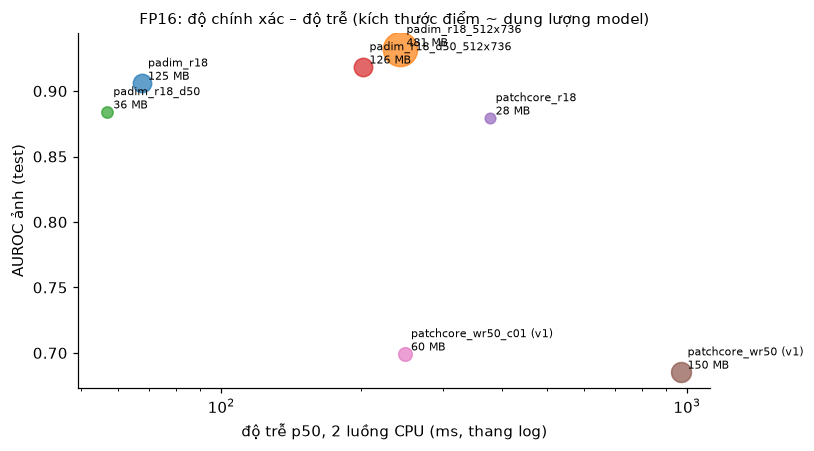

In [8]:
v1 = pd.DataFrame(json.loads(Path("reports/zoo_v1_randomval_rows.json").read_text()))
v1 = v1[v1.model.str.startswith("patchcore_wr50")]
allr = pd.concat([rows, v1.assign(model=v1.model + " (v1)")])
fp16 = allr[allr.precision == "fp16"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for _, r in fp16.iterrows():
    ax.scatter(r.p50_ms, r.image_AUROC, s=20 + r.model_mb, alpha=0.7)
    ax.annotate(f"{r.model}\n{r.model_mb:.0f} MB", (r.p50_ms, r.image_AUROC), fontsize=7, xytext=(4, 2),
                textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("độ trễ p50, 2 luồng CPU (ms, thang log)")
ax.set_ylabel("AUROC ảnh (test)")
ax.set_title("FP16: độ chính xác – độ trễ (kích thước điểm ~ dung lượng model)", fontsize=10)
plt.tight_layout()
plt.show()

- **PaDiM-R18** cho AUROC cao nhất ở mức ~60–70 ms/ảnh (2 luồng) → lựa chọn cho máy yếu.
- **PatchCore** chậm hơn 5–15 lần (tìm láng giềng gần nhất trong bộ nhớ hàng chục nghìn vector đặc trưng) mà
  không chính xác hơn trên dữ liệu này; WR50 còn kém hơn R18 (AUROC 0.69–0.70).
- **512×736** tăng AUROC (PaDiM-R18 0.906 → 0.932) nhờ lỗi nhỏ rõ hơn, đổi lại chậm ~3,6 lần (≈ 240 ms) và model
  FP16 481 MB (ma trận hiệp phương sai của PaDiM tăng theo số vị trí).
- Thiết bị đo là CPU Xeon của Colab giới hạn 2 luồng — **chỉ là đại diện** cho PC công nghiệp; cần đo lại trên
  máy thật (lệnh `partinspect-serve` in độ trễ từng ảnh).

### 3.2 Mức nén

In [9]:
prec = rows[rows.model.isin(["padim_r18", "padim_r18_d50", "patchcore_r18", "padim_r18_512x736"])]
prec.pivot_table(index="model", columns="precision", values=["image_AUROC", "model_mb", "p50_ms"]).round(3)

image_AUROC                        model_mb                              p50_ms                           
precision                fp16   fp32   int8 int8_ptq     fp16     fp32     int8 int8_ptq     fp16     fp32     int8 int8_ptq
model                                                                                                                       
padim_r18               0.906  0.906  0.913    0.869  124.587  249.066   65.923   66.535   67.580   67.280   66.685   51.707
padim_r18_512x736       0.932  0.932  0.937    0.942  481.400  962.692  254.928  257.306  242.505  241.008  239.220  168.480
padim_r18_d50           0.884  0.884  0.893    0.864   35.678   71.248   19.702   20.019   56.918   57.740   57.313   47.220
patchcore_r18           0.880  0.881  0.873    0.848   28.473   56.792   14.527   60.015  377.010  376.007  376.660  370.338

- **FP16**: độ chính xác *trùng khít* FP32, dung lượng ½ → mặc định nên dùng.
- **INT8 trọng số**: AUROC giữ nguyên (±0.01), dung lượng ¼, nhưng **không nhanh hơn** (trọng số được giải nén
  về FP32 khi tính). Hữu ích khi thiếu bộ nhớ/ổ đĩa, không phải khi thiếu tốc độ.
- **INT8 PTQ**: nhanh hơn ~20–25% (PaDiM 67 → 52 ms) nhưng AUROC giảm (0.906 → 0.869) và phân bố điểm lệch đi
  nên phải chọn lại ngưỡng. Phép tính khoảng cách Mahalanobis của PaDiM (một MatMul) nhạy với lượng tử hoá.
  Thử bỏ qua MatMul khi lượng tử hoá (`int8_cnn`) còn kém hơn, nên không giữ.
- Lỗi kỹ thuật đã gặp và sửa trong pipeline: export PatchCore bị cố định batch = 2 (đã cố định batch = 1);
  PTQ của anomalib không chạy với input kích thước động (tự gọi NNCF); ghi đè `model.bin` đang được mmap làm
  tiến trình chết (SIGBUS) → ghi ra file tạm rồi đổi tên.

## 4. Model bắt được những lỗi nào?

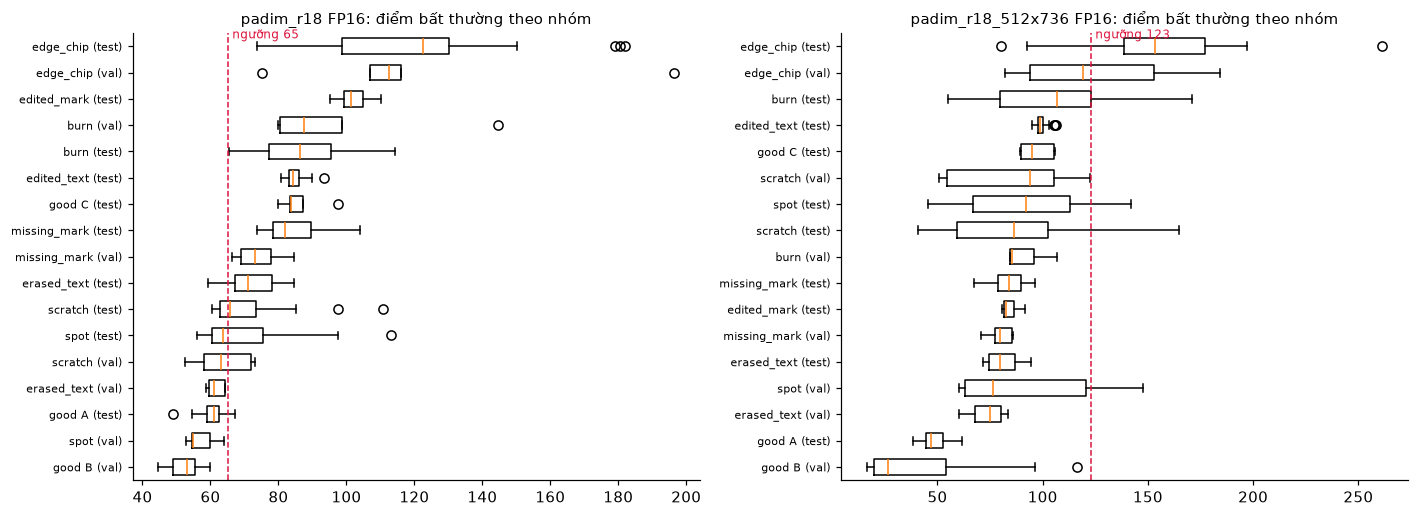

In [10]:
def scores(model, precision="fp16"):
    d = pd.read_csv(RESULTS / model / f"scores_{precision}.csv").fillna("")
    part = np.where(d.path.str.contains("new_"), "C", np.where(d.split == "val", "B", "A"))
    d["group"] = np.where(d.label == "good", "good " + pd.Series(part) + " (" + d.split + ")", d.defect_type + " (" + d.split + ")")
    return d


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
for ax, model in zip(axes, ["padim_r18", "padim_r18_512x736"]):
    d = scores(model)
    order = d.groupby("group").score.median().sort_values().index
    ax.boxplot([d[d.group == g].score for g in order], orientation="horizontal", tick_labels=order, widths=0.6)
    th = json.loads((RESULTS / model / "results.json").read_text())["precisions"]["fp16"]["thresholds"]["good_3sd"]
    ax.axvline(th, color="crimson", ls="--", lw=1)
    ax.text(th, len(order) + 0.3, f" ngưỡng {th:.0f}", color="crimson", fontsize=8)
    ax.set_title(f"{model} FP16: điểm bất thường theo nhóm", fontsize=10)
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

- Lỗi lớn (mẻ cạnh, mất dấu tròn, ảnh chỉnh sửa, vết cháy) có điểm cao hơn hẳn ảnh tốt → bắt tốt.
- **Vết xước và chấm bẩn** nhỏ (0,5–2% diện tích) ở 256×368 chỉ còn vài pixel; điểm chồng lên ảnh tốt → recall
  thấp (25–50%). Ở 512×736 điểm của chúng tách ra rõ hơn.
- **Ảnh good của chi tiết C** (chi tiết model chưa từng thấy) có điểm ngang ảnh lỗi → sẽ bị loại nhầm. Đây là vấn
  đề chính của bộ dữ liệu, xem mục 5.
- Ở 512×736, ảnh good A (test) có điểm cao hơn hẳn ảnh good B (val): độ phân giải cao "nhớ" vân bề mặt của từng
  chi tiết kỹ hơn, nên ngưỡng chọn trên val (chi tiết B) không áp dụng được cho chi tiết A.

### Bắt lỗi khi gặp chi tiết chưa thấy
Chỉ 5 ảnh của chi tiết C là "hàng tốt mới" thật sự; AUROC tính riêng với nhóm này (quá ít ảnh để kết luận chắc):

In [11]:
out = []
for model in ["padim_r18", "padim_r18_d50", "patchcore_r18", "padim_r18_512x736"]:
    d = scores(model)
    t = d[d.split == "test"]
    ng = t[t.label == "NG"].score
    for name, good in [("good A (chi tiết đã thấy)", t[t.group.str.startswith("good A")].score),
                       ("good C (chi tiết mới)", t[t.group.str.startswith("good C")].score)]:
        y = np.r_[np.zeros(len(good)), np.ones(len(ng))]
        out.append({"model": model, "good": name, "n_good": len(good),
                    "AUROC": metrics.roc_auc_score(y, np.r_[good, ng])})
pd.DataFrame(out).pivot(index="model", columns="good", values="AUROC").round(3)

good,good A (chi tiết đã thấy),good C (chi tiết mới)
model,,
padim_r18,0.942,0.476
padim_r18_512x736,0.977,0.387
padim_r18_d50,0.941,0.202
patchcore_r18,0.908,0.542


## 5. Vì sao chưa đặt được ngưỡng đáng tin trên bộ dữ liệu này

Đã thử ba cách chọn ngưỡng, cả ba đều không ổn định:

| Cách | Kết quả (PaDiM-R18) | Nguyên nhân |
|---|---|---|
| val ngẫu nhiên 20 ảnh | 512×736: FPR test 0.74–0.88 | ảnh val có ảnh hàng xóm (gần như giống hệt) trong train |
| val là khối liên tục 271–300 | 256: recall 0.97 nhưng FPR 0.71 (ngưỡng max) hoặc recall 0.86 / FPR 0.14 (3σ); 512: recall chỉ 0.17 | 30 ảnh của *một* chi tiết (B) không đại diện cho chi tiết A trong test |
| k-fold 5 khối (`partinspect-calibrate`), ngưỡng = p99 điểm out-of-fold | recall 0.36, FPR 0.015 | fold chứa phần cuối của chi tiết A (065–094) bị chấm điểm cao (~79) khi model học chủ yếu chi tiết B → ngưỡng bị đẩy lên |

Chuẩn hoá độ sáng (`partinspect-normalize`; độ sáng giảm dần ~5% theo thứ tự chụp) không thay đổi kết quả k-fold.
Nguyên nhân gốc là **bộ dữ liệu chỉ có 3 chi tiết vật lý** (mục 1): biến thiên giữa các chi tiết tốt (vân bề mặt,
vết dòng chảy nhựa) chưa bao giờ được quan sát đủ, nên không ước lượng được tỉ lệ loại nhầm hàng tốt mới.

In [12]:
cal = []
for f in sorted(Path("results_cal").glob("*/calibration.json")):
    c = json.loads(f.read_text())
    for fold in c["folds"]:
        cal.append({"config": f.parent.name, "fold": fold["fold"], "held out": "–".join(fold["held_out"]),
                    "OOF good median": fold["oof_median"], "OOF good max": fold["oof_max"]})
pd.DataFrame(cal).round(1) if cal else "results_cal/ không có (k-fold chưa được chạy trên máy này)"

,config,fold,held out,OOF good median,OOF good max
0,padim_r18_256x368_fp16,0,065.png–110.png,79.3,90.9
1,padim_r18_256x368_fp16,1,111.png–156.png,55.1,67.3
2,padim_r18_256x368_fp16,2,157.png–203.png,55.5,68.8
3,padim_r18_256x368_fp16,3,204.png–249.png,55.1,72.2
4,padim_r18_256x368_fp16,4,250.png–300.png,53.3,62.6
5,padim_r18_d50_256x368_fp16,0,065.png–110.png,61.0,67.9
6,padim_r18_d50_256x368_fp16,1,111.png–156.png,36.2,48.1
7,padim_r18_d50_256x368_fp16,2,157.png–203.png,37.5,46.2
8,padim_r18_d50_256x368_fp16,3,204.png–249.png,36.0,51.2
9,padim_r18_d50_256x368_fp16,4,250.png–300.png,36.9,46.0


## 6. Nguyên mẫu trạm kiểm tra (`partinspect-serve`)

```
camera ──ảnh──▶ thư mục incoming/ ──▶ partinspect-serve ──▶ tín hiệu PASS/REJECT (stub → digital output / PLC)
                                            │
                                            ├─▶ inspections.csv (thời gian, file, điểm, OK/NG, độ trễ, cảnh báo)
                                            ├─▶ ng/<ảnh>_ng.jpg (heatmap vị trí lỗi)
                                            └─▶ cảnh báo trôi: median điểm hàng OK lệch > 3σ so với lúc hiệu chỉnh,
                                                hoặc tỉ lệ NG trong 50 chi tiết gần nhất > 20%
```
Máy trạm chỉ cần `pip install openvino opencv-python-headless` và thư mục `models/` + `deploy/line_example.json`.

In [13]:
cfg_path = PROJECT / "deploy/line_example.json"
model_xml = PROJECT / "models/padim_r18_256x368_fp16/model.xml"
if model_xml.exists():
    import shutil

    from partinspect.deploy import Station, watch

    demo_in, demo_out = PROJECT / "outputs/station_demo/incoming", PROJECT / "outputs/station_demo/run"
    shutil.rmtree(demo_in.parent, ignore_errors=True)
    demo_in.mkdir(parents=True)
    pick = pd.concat([man[(man.split == "test") & man.path.str.contains("orig_0[01]")],
                      man[man.path.str.contains("new_")],
                      man[man.path.str.contains("edited_00[0-4]")],
                      man[(man.split == "test") & (man.defect_type == "scratch")].head(5)])
    for i, p in enumerate(pick.path):
        shutil.copyfile(DATA / p, demo_in / f"{i:03d}_{Path(p).name}")
    cfg = json.loads(cfg_path.read_text())
    cfg["model"] = str(model_xml)
    watch(Station(cfg, demo_out), demo_in, once=True)
    log = pd.read_csv(demo_out / "inspections.csv")
    print(log.groupby(log.file.str.extract(r"\d+_(orig|new|edited|synth)")[0]).decision.value_counts().unstack(fill_value=0))
else:
    print("Chưa có models/ → bỏ qua demo. Kết quả demo đã chạy trên Colab: docs/station_demo_inspections.csv")
    print(pd.read_csv(PROJECT / "docs/station_demo_inspections.csv")[["file", "score", "decision", "latency_ms"]].to_string())

000_orig_000.png: OK score 57.9 (218 ms)


001_orig_001.png: OK score 63.5 (83 ms)


002_orig_002.png: OK score 62.7 (79 ms)


003_orig_003.png: OK score 65.2 (77 ms)


004_orig_004.png: OK score 61.7 (78 ms)


005_orig_005.png: OK score 59.6 (77 ms)


... (26 outputs left out)

032_synth_scratch_043.png: NG score 109.2 (80 ms)


033_synth_scratch_044.png: OK score 64.0 (81 ms)


034_synth_scratch_045.png: OK score 61.3 (78 ms)


decision  NG  OK
0               
edited     5   0
new        5   0
orig       0  20
synth      2   3


**Lưu ý:** cùng một file model, điểm trên Mac (CPU ARM) lệch ~1 điểm so với Colab (x86), ví dụ `orig_003`:
65.2 (OK) trên Mac, 65.9 (NG) trên Colab — sát ngưỡng 65.2. Vì vậy ngưỡng phải được hiệu chỉnh trên chính máy
triển khai, không chép từ máy phát triển.

Ảnh heatmap mà trạm lưu cho các chi tiết NG (demo trên Colab):

![overlays](../docs/station_overlays.jpg)

### Giám sát trôi phân bố
Mô phỏng: 100 chi tiết tốt của chi tiết A, sau đó dây chuyền chuyển sang lô chi tiết C (5 ảnh, lặp lại). Bộ giám
sát báo động khi median điểm của hàng OK lệch quá 3σ, hoặc khi tỉ lệ NG trong cửa sổ vượt 20% — tín hiệu để dừng và
hiệu chỉnh lại ngưỡng với chi tiết tốt của lô mới.

báo động tại chi tiết thứ 109: ['NG rate 22% over the last 50 parts']


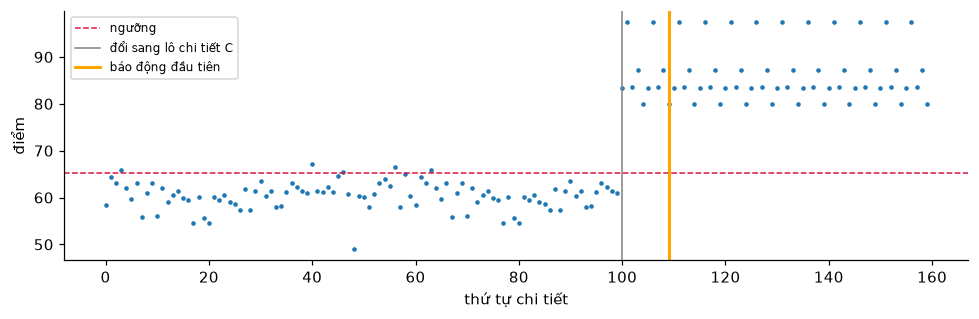

In [14]:
from partinspect.deploy import DriftMonitor

d = scores("padim_r18")
cfg = json.loads(cfg_path.read_text())
mon = DriftMonitor(**{k: cfg["drift"][k] for k in ("ref_median", "ref_spread", "window", "max_shift", "max_ng_rate")})
a_scores = d[d.group.str.startswith("good A")].score.to_numpy()
c_scores = d[d.group.str.startswith("good C")].score.to_numpy()
stream = np.r_[np.resize(a_scores, 100), np.resize(c_scores, 60)]
first_alarm = None
for i, s in enumerate(stream):
    alarms = mon.update(s, s < cfg["threshold"])
    if alarms and first_alarm is None:
        first_alarm = (i, alarms)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(stream, ".", ms=4)
ax.axhline(cfg["threshold"], color="crimson", ls="--", lw=1, label="ngưỡng")
ax.axvline(100, color="gray", lw=1, label="đổi sang lô chi tiết C")
if first_alarm:
    ax.axvline(first_alarm[0], color="orange", lw=2, label="báo động đầu tiên")
    print(f"báo động tại chi tiết thứ {first_alarm[0]}: {first_alarm[1]}")
ax.set_xlabel("thứ tự chi tiết")
ax.set_ylabel("điểm")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Kết luận

**Đã làm được**
- Phát hiện và loại bỏ rò rỉ dữ liệu khiến kết quả cũ đạt AUROC ~1.0; bộ công cụ kiểm tra (`partinspect-audit`)
  dùng lại được cho bộ dữ liệu khác.
- Pipeline có thể chạy lại: chia dữ liệu sạch, lỗi tổng hợp có mask chính xác, huấn luyện + export + đánh giá chính
  file triển khai, đo độ trễ trên CPU 2 luồng, báo cáo theo từng loại lỗi.
- Chọn được cấu hình cho máy yếu: **PaDiM-R18, FP16, 256×368, OpenVINO** — ~67 ms/ảnh với 2 luồng (≈ 15 chi
  tiết/giây), 125 MB; AUROC 0.906 trên test sạch; bắt gần như hết lỗi lớn. Nếu dây chuyền cho phép ~240 ms/ảnh,
  512×736 bắt lỗi nhỏ tốt hơn (AUROC 0.932).
- Nguyên mẫu trạm kiểm tra có log, ảnh heatmap, tín hiệu OK/NG và cảnh báo trôi.

**Hạn chế (cần nói rõ khi bảo vệ)**
- Chỉ có 3 chi tiết vật lý → **không ước lượng được tỉ lệ loại nhầm hàng tốt mới**; chi tiết C (5 ảnh) bị chấm
  như hàng lỗi. Các con số recall/FPR ở trên chỉ đúng cho chi tiết đã thấy.
- Lỗi trong test là lỗi tổng hợp và lỗi vẽ bằng Photoshop, chưa có lỗi thật.
- Độ trễ đo trên Xeon (Colab) giới hạn 2 luồng, chưa đo trên PC công nghiệp thật.

**Hướng tiếp theo**
1. Chụp thêm 20–50 chi tiết tốt *khác nhau* (mỗi chi tiết 2–3 tấm) và các chi tiết lỗi thật; chạy lại
   `partinspect-audit` → `partinspect-split` → `partinspect-calibrate` (k-fold theo chi tiết).
2. Đánh giá trên benchmark công khai có lỗi thật (VisA, MVTec AD) để có số liệu so sánh được.
3. Lỗi nhỏ: chia ảnh thành ô (tiling) ở độ phân giải gốc thay vì tăng độ phân giải cả ảnh.